# Proof of concept — do the hypotheses hold on the toy set? (run 3: the conditions the contributions need)

This notebook tests the hypotheses of MIL-CREDA on one toy scenario, `rollo`
with the BatchNorm MLP, and states for each one **VALIDATED** or **NOT
VALIDATED** by a rule written down before any result. It holds **run 3**:
the battery re-run under the conditions §0 derives from the proposal's own
mechanisms. Runs 1 and 2 are summarised under "Earlier runs" and compared at
the end. Their records stay in `Results/PoC/` and `Results/PoC_SubjectShift/`,
and run 1's executed notebook is git commit `75a4f91`.

| Section | Hypothesis tested here |
|---|---|
| H-task | MIL-CREDA (global + local, TGL) beats the source-only floor on the target |
| K1 | Own attention gives less weight to contaminated instances than to clean ones, and more so than the own mechanism without consensus: donor-class contamination (run-1 family) and artifact contamination (new, separate family) |
| K2 | A target bag lies closer to its own partner source bag than to the others, and more so with the local term than without it |
| K3 | Own mechanism > own without consensus; both terms > global only; both terms > local only: on clean bags (run-1 family) and on artifact-contaminated bags (new, separate family) |

## 0. What each contribution needs from the data before it can show anything

Each contribution below is stated by its mechanism in r38. Then come (a) the mechanism, (b) when it must make a measurable difference and when it provably cannot, (c) what the current rollo toy lacks, with evidence, and (d) the minimal toy change that creates the missing condition. Every arm, floor and reference must see that change identically.

### 0.0 A precondition shared by K2 and K3: what a phase-2 step contains

- **Mechanism.** The local term (Eq. 34) spreads each target bag's class mass over the source bags of that class *in the step's source collection*. This is π_{ji|c}, a softmax over i ∈ S_c. Its reference μ_j (Eq. 36) is "personalised" only if |S_c| > 1. The global term (Eqs. 28–33) builds per-class Gram blocks over the same step's bags.
- **Provably inert regime.** With exactly one source bag per class in the step, π_{ji|c} = 1 identically. Then μ_j = Σ_c g_{jc} Ψ(B_c^s): a class mixture of whichever source bag was sampled, with no choice among subjects. With about one target bag per pseudo-class, the global block K_c^s is 1×1 and the global term reduces to pulling the step's target bags toward that same source bag. So the two terms push toward the same target. "Local adds to global" (K2b, K3b) and "global adds to local" (K3c) cannot be expected.
- **What the toy does.** `harness.balanced_batches` yields one bag of every class per step (`src/MIL_CREDA_Benchmark/harness.py:63-87`, loop at :79). `material_bound` sets `config.BAGS_PER_STEP = scale.classes` = 3 (`toy_run.py:574`). The target draw takes `config.BAGS_PER_STEP` bags (`wiring.py:623-629`). Every phase-2 step of both PoC runs therefore had |S_c| = 1 and about 1 target bag per class.
- **Minimal change.** Add an option, default off, for k > 1 source bags per class per step, with k·C target bags. It applies to every adaptation arm (TGL, TG, TL, TGL-NC, references) identically. It is not a data change; it is the condition Eq. 34 needs to be more than an identity.
- **Consequence for the full run.** The EEG trainer takes `bagsPerStep` as an input that only has to be at least the number of classes (`src/MIL_CREDA_EEG/two_phase.py:205`). The pilot schedule uses 4 with 2 classes (`campaign.py:1379`), i.e. 2 source bags per class. The same degeneracy is reachable there at `bagsPerStep = 2`.

### 0.1 Contribution 1: the consensus in the attention (K1, and K3a)

- **(a) Mechanism.** The logit is ν = R_φ(h) + γ·(1/(m−1)) Σ_{a'≠a} κ_σ(h, h_{a'}) (Eq. 15), and β = softmax(ν/τ_att) (Eq. 16).
  - R_φ depends on the instance alone: the same embedding gets the same relevance in every bag and in both domains (§3.2).
  - Only the consensus depends on the instance's own bag.
- **(b) When it must and cannot matter.**
  - **Relevance provably cannot** systematically down-weight an instance that is atypical *for its bag* but typical *globally*. The same point is a clean witness in a bag of its own class. With the cyclic donor map (every class is both a contaminant and a clean class), any class preference R learns cancels or flips sign across bags; it cannot be positive by construction.
  - **Consensus can** separate them, because a contaminant has low kernel affinity to the rest of its bag.
  - **The size of the consensus effect is bounded by σ.** With σ = 0.5 × the within-bag median distance (`poc.py:73`), a clean pair at the median distance has κ = e^{−2} ≈ 0.135. So the clean-vs-contaminant consensus gap is at most about that. The logit gap is at most γ·gap/τ_att ≈ 0.863 × 0.135 / 0.426 ≈ 0.27, a weight ratio of about 1.3. This is an arithmetic bound, not a measurement.
  - **Accuracy (K3a)** can gain from consensus only if atypical instances move the bag representation enough to change the decision. On clean bags every instance of a band carries the same class evidence, so consensus provably cannot improve accuracy there.
- **(c) What rollo has and lacks.**
  - *Has:* the bag-relative contamination (`bags.py:196` seam, donor class, label kept). This is exactly the regime that separates consensus from relevance, and K1b passed at all three rates in both runs.
  - *Lacks, condition 1:* the protocol's marked windows (sample loss, bad contact) are atypical *globally* as well, off the signal manifold and large in amplitude. Toy contaminants are valid points of another class.
  - *Lacks, condition 2:* the K3 ladder ran on clean bags (rate 0), where K3a cannot show anything.
  - *Lacks, condition 3:* at r ≤ 0.3 the bag majority decides, so mean pooling already classifies. Measured target accuracy for mean / TGL / TGL-NC: 0.863 / 0.809 / 0.885 at r=0.1, 0.869 / 0.804 / 0.819 at r=0.2, 0.857 / 0.857 / 0.861 at r=0.3 (`Results/PoC/raw_results.json`).
- **(d) Minimal change.**
  - Add an "artifact" contamination mode through the same seam: replaced instances are off-manifold points (e.g. the clean instance plus isotropic noise of declared scale), in both domains, for all arms.
  - Relevance and ABMIL can then also detect them, which is the protocol's setting. K1b then asks whether consensus adds anything beyond relevance.
  - Run K3a on that material, because an unbounded outlier corrupts a mean and only a weighting that ignores it can recover the decision.
  - Keep the donor-class mode as the regime where only consensus can act.
  - Do **not** touch γ, τ_att or the σ multiplier: enlarging the consensus effect by choosing them after seeing the results would favour the method.

**K1 at r = 0.1, from the mechanism.** The measured contrast splits additively:
- TGL-NC (relevance only) is −0.264, −0.174, −0.082 at r = 0.1, 0.2, 0.3. The bag-agnostic relevance carries a negative bias: it up-weights contaminants.
- TGL − TGL-NC is roughly constant: HL 0.22, 0.22, 0.26. This is the consensus gain, capped by the σ bound above.
- So c(TGL) ≈ bias + 0.22, which comes to −0.07 at r = 0.1 (fails), +0.08 at r = 0.2 and +0.20 at r = 0.3.
- The bias shrinks with r because supervision only pressures the attention once contaminants threaten the bag's decision. With 27 of 30 instances clean, the loss is already low and nothing removes the relevance bias.

This reading is inferred from the measured decomposition; I did not trace the gradient.

### 0.2 Contribution 3: local alignment toward personalised source references (K2, K3b)

- **(a) Mechanism.** π_{ji} = g_{jc}·softmax_{i∈S_c}(κ^B(i,j)/τ_loc) (Eqs. 34–35), μ_j = Σ π_{ji} Ψ(B_i^s) (Eq. 36), d_j² = ‖Ψ(B_j^t) − μ_j‖² (Eqs. 37–38). θ_t is the only thing trained, and it is one shared encoder applied instance by instance.
- **(b) When it must and cannot matter.** Local adds to global only when all four hold:
  1. Bags of one class are not exchangeable, i.e. there are distinct subjects within a class.
  2. The needed correction differs between subjects.
  3. That correction is learnable by a shared instance-level encoder. The encoder never sees a bag id, so a subject-specific shift is correctable only if it is a function of the instance's position. If shifted subjects overlap, no encoder can undo it, for any arm.
  4. At adaptation time the kernel-nearest same-class source bags include the partner. The correspondence comes from κ^B and does not discover the true partner; it reinforces whatever the current geometry says.

  Local **provably** adds nothing when:
  - the shift is shared by every bag: one θ_t correction serves all, and global and local are minimised by the same θ_t;
  - |S_c| = 1 per step (§0.0);
  - the per-subject shift is not a function of position (uncorrectable for everyone).

  The global term is invariant to permuting bags within a class. So a deformation that preserves the class-conditional bag distribution but moves bags relative to their partners is invisible to global and visible to local. That is the case where K2b should pass.
- **(c) What rollo lacks.**
  - Run 1: the shift is shared (`CREDA/toy_experiment.py:124-126`).
  - Run 2: the per-pair shift was drawn independently per pair (`toy_bags.py:252-254`). Bags are long slabs spanning the full height h ∈ [0, 12] (`toy_experiment.py:155`), with mean point radius about 3.1 and neighbouring centroids 1.1 apart. Independently shifted pairs therefore overlap, and the deformation is not a function of position, which violates condition 3. That matches TL losing about 6 pp while K2b moved the wrong way.
  - Both runs had |S_c| = 1 (§0.0).
- **(d) Minimal change.** §0.0 first (k > 1). Then replace the independent per-pair draw with a **smooth subject field**: each target band's displacement is a smooth, low-frequency function of its position along the roll's parameter t (the band index). It is invertible, so a shared encoder can learn it. Its amplitude is declared below the spacing of neighbouring same-class bags in input space, so the partner stays the nearest same-class bag (condition 4).

  Every arm sees the same target. Choosing the regime where condition 4 holds is choosing where the mechanism can work. The result can then show "the local term works when subjects are identifiable and shifted differently". It cannot show that EEG subjects satisfy that.

### 0.3 Contribution 2: class-conditional global alignment (K3c, and H-task)

- **(a) Mechanism.** Per class, J_c contrasts the two trace-normalised marginal entropies with that of the balanced mixture, each domain contributing mass ½ (Eqs. 28–29). The loss is (U_c − J_c)/const (Eqs. 31–32). Classes are weighted by source counts, and an abandoned class is charged 1 (Eq. 33).
- **(b) When it must and cannot matter.** Global adds to local (K3c) where local alone goes wrong: when pseudo-labels are wrong or imbalanced, so π puts mass on the wrong class and nothing in L_loc balances the classes. The global term's per-domain mass of ½ and its abandoned-class charge do. With few routing errors to begin with, global has little to correct beyond what local already does.
- **(c) What rollo lacks.**
  - In phase 2 θ_t runs in training mode (`toy_run.py:1276`), so its BatchNorm normalises each target batch with its own statistics. The 17-unit shared translation is removed from the first step, which is effectively AdaBN.
  - Measured: AdaBN 0.794 vs TGL 0.839 vs source-only 0.352 (run 1). Arms start near 0.79 with about 4.5 pp of headroom, less than one test bag: 18 test bags means a step of 5.6 pp.
  - The rotation, the only part BatchNorm cannot close, is 10°. `perturbar`'s own measurement has AdaBN falling 0.765 → 0.594 between 0° and 60° (`toy_experiment.py:112-117`).
- **(d) Minimal change.** A larger declared Σ-preserving rotation (e.g. 20–30°) creates routing errors and headroom for every arm alike. `perturbar`'s docstring measured CREDA's margin over AdaBN *shrinking* with angle, so this does not tilt toward the method. Separately, a resolution fix: more test bags per domain at the same density, a programme change that applies to every arm.

### 0.4 What cannot be created on a toy without favouring the method

- **Tuning to the method.** Choosing γ, τ_att or the σ multiplier to enlarge the consensus effect, or the subject-field amplitude after seeing results, would favour the method. These stay at the archived values, or are declared before any run.
- **Subject identity readable from the instance.** On the toy we create this by construction (bands are separable along t). It is a *property of the data* that EEG may or may not have, and no toy result can establish it for EEG. A toy K2 pass would mean "the mechanism works when its precondition holds", nothing more.
- Neither of these gives MIL-CREDA material the comparators lack: every change acts on the shared data or on the shared step composition.

## Earlier runs

- **Run 1** (`Results/PoC/`, commit 75a4f91): rollo with its global target shift.
  **H-task VALIDATED**; K1 NOT VALIDATED (5 of 6 tests pass; c(TGL) > 0 fails
  at r = 0.1); K2 NOT VALIDATED (separation > 0 passes, the local term adds
  nothing over global only); K3 NOT VALIDATED (the four rungs tie).
- **Run 2** (`Results/PoC_SubjectShift/`, commit 71f0a37): run 1 plus an
  independent per-pair target shift. Same verdicts: 1 of 4 validated. TL lost
  about 6 pp and K2b moved the wrong way.
- **Why run 3.** §0 shows that both runs lacked conditions the mechanisms
  need: one source bag per class per step (π_{ji|c} ≡ 1), a shared shift (run
  1) or one no encoder can invert (run 2), no globally atypical contamination,
  clean bags for the consensus rung, and too little headroom and resolution
  (18 test bags, AdaBN 4.5 pp below TGL).

## Where the repository is

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


## Tools

Everything that trains or measures comes from `MIL_CREDA_Benchmark.poc`, which
reuses the benchmark as it is: bags from `bags.build`, arms from `wiring`, the
phase helpers from `toy_run`, and the tutorial's two training loops lifted into
functions. Run 3's conditions are one `poc.Conditions` value (`poc.RUN3`), and
every arm, floor and reference of a seed runs under it.

In [2]:
import dataclasses
import hashlib
import json
import os
import sys
import time
from datetime import datetime, timezone

REPOSITORY = ROOT
SRC = str(REPOSITORY / "src")
sys.path.insert(0, SRC)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from CREDA import toy_experiment
from MIL_CREDA_Benchmark import config, poc, toy_bags, toy_run

RESULTS = REPOSITORY / "MIL-CREDA" / "Results" / "PoC_Conditions"
RUN1 = REPOSITORY / "MIL-CREDA" / "Results" / "PoC"
RUN2 = REPOSITORY / "MIL-CREDA" / "Results" / "PoC_SubjectShift"
RESULTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)
SCALE = poc.CONDITIONS_SCALE
CLEAN = poc.RUN3
ARTIFACT = dataclasses.replace(poc.RUN3, contamination="artifact")
print("repository:", REPOSITORY)
print("revision:  ", config.REVISION)
print("scenario:  ", poc.FAMILY, "/", poc.BACKBONE, "(BatchNorm)")
print("scale:     ", SCALE.name, "- epochs", SCALE.epochs_1, "/", SCALE.epochs_2,
      "- patience", SCALE.patience_1, "-", SCALE.points_per_domain, "points/domain,",
      SCALE.bags_per_class, "bags/class", SCALE.realized_split()["bagsPerClass"])
print("conditions:", dataclasses.asdict(CLEAN))

repository: /Users/diego/Proyectos/MIL-CREDA/implementations/Domain_Adaptation
revision:   research-concept-r38.md
scenario:   rollo / mlp (BatchNorm)
scale:      conditions - epochs 100 / 100 - patience 30 - 5850 points/domain, 39 bags/class {'train': 16, 'valid': 5, 'test': 18}
conditions: {'per_pair_shift': 0.0, 'rotation_degrees': 25.0, 'subject_field': 0.45, 'source_bags_per_class': 4, 'contamination': 'donor'}


## Run-3 conditions (fixed by the parent before any result, declared here)

| Condition | Value | From |
|---|---|---|
| Source bags per class per phase-2 step | k = 4, with 4·C = 12 target bags; same number of epochs, so each domain's bags are seen as often as in runs 1–2 (4 steps × 12 = 16 steps × 3 bags per pass); phase 1 unchanged | §0.0 |
| Test bags per domain | 54 (18 per class) instead of 18, at the same density (50 points per bag): 39 bags per class (16 train / 5 valid / 18 test), 5,850 points per domain | §0.3 |
| Σ-preserving rotation | 25° (was 10°) | §0.3 |
| Subject field | each target point slid **along** the roll by `A·sin(2π·3·(t − t0)/L + φ)` in t, with A = 0.45 × the smallest gap between neighbouring same-class band medians (both raw draws), φ seeded; invertible, smooth, height kept | §0.2 condition 4 |
| Artifact contamination | the slots `bags._contaminate` picks, holding the clean instance + isotropic noise of sd = 1.0 × the domain's clean coordinate spread `esc` | §0.1 |
| K3 on artifact bags | rate 0.2 (the middle of the K1 sweep) | §0.1 |
| γ, τ_att, σ multiplier, every hyperparameter | unchanged from `Results/PoC/preregistration.json` | §0.4 |
| Run 2's per-pair shift | off (replaced by the subject field) | §0.2 |

The next cell measures each condition from the generator alone (no model is
trained), so its size is on the page before any result.

In [3]:
SEEDS0 = 10
f_base = toy_run.build_family(poc.FAMILY, SEEDS0, SCALE)
f_on = toy_run.build_family(poc.FAMILY, SEEDS0, SCALE, **CLEAN.draw_options())
field = f_on.campo
t_src = toy_bags.parametro("rollo", f_on.Xs)
t_raw = toy_bags.parametro("rollo", f_on.Xt_crudo)
moved = toy_bags.campo_de_sujeto(f_on.Xt_crudo, field["amplitudT"], field["periodos"], field["fase"])
t_mov = toy_bags.parametro("rollo", moved)


def same_class_centroid_gap(X, y, b):
    gaps = []
    for c in np.unique(y):
        C = np.array([X[(y == c) & (b == k)].mean(0) for k in np.unique(b[y == c])])
        D = np.linalg.norm(C[:, None] - C[None], axis=-1)
        np.fill_diagonal(D, np.inf)
        gaps.append(D.min(1))
    return np.concatenate(gaps)


def partner_nearest_share(t_target):
    hits = total = 0
    for c in np.unique(f_on.ys):
        bands = np.unique(f_on.bs[f_on.ys == c])
        centres = np.array([np.median(t_src[(f_on.ys == c) & (f_on.bs == k)]) for k in bands])
        for k in bands:
            centre = np.median(t_target[(f_on.yt == c) & (f_on.bt == k)])
            hits += bands[np.argmin(np.abs(centres - centre))] == k
            total += 1
    return hits / total


gap = same_class_centroid_gap(f_on.Xt_crudo, f_on.yt, f_on.bt)
arc = np.linalg.norm(moved - f_on.Xt_crudo, axis=1)
esc_s, esc_t = float(f_on.Xs.std(0).mean()), float(f_on.Xt.std(0).mean())
Hs, _ = toy_experiment._raiz(np.cov(f_on.Xs.T))
_, Hti = toy_experiment._raiz(np.cov(moved.T))
centred = moved - moved.mean(0)
rot = {}
for g in (10.0, 25.0):
    A = Hs @ toy_experiment._rotacion_generica(np.radians(g)) @ Hti
    rot[g] = float(np.linalg.norm(centred @ A.T - centred, axis=1).mean())
geometry = pd.DataFrame([
    {"quantity": "test bags per domain (per class)", "value": f"{3 * SCALE.realized_split()['bagsPerClass']['test']} ({SCALE.realized_split()['bagsPerClass']['test']})"},
    {"quantity": "points per bag (density)", "value": SCALE.points_per_domain / (3 * SCALE.bags_per_class)},
    {"quantity": "smallest same-class band gap, t", "value": field["espaciadoMinimoT"]},
    {"quantity": "field amplitude A, t (0.45 x gap)", "value": field["amplitudT"]},
    {"quantity": "field: mean / max displacement in input space", "value": f"{arc.mean():.3f} / {arc.max():.3f}"},
    {"quantity": "neighbouring same-class bag centroid gap, input space (min / median)", "value": f"{gap.min():.3f} / {np.median(gap):.3f}"},
    {"quantity": "target bags whose band median is nearest the partner's, field off", "value": partner_nearest_share(t_raw)},
    {"quantity": "same, field on", "value": partner_nearest_share(t_mov)},
    {"quantity": "global rotation displacement, 10 deg / 25 deg", "value": f"{rot[10.0]:.3f} / {rot[25.0]:.3f}"},
    {"quantity": "artifact noise sd per coordinate (source / target) = 1.0 esc", "value": f"{esc_s:.3f} / {esc_t:.3f}"},
]).set_index("quantity")
display(Markdown(f"**Measured conditions, seed {SEEDS0}, generator only (no model)**"))
display(geometry)
print("field invertible along t (strictly increasing on a grid):",
      bool(np.all(np.diff(toy_bags.t_bajo_campo(np.linspace(*toy_bags.T_ROLLO, 20001),
                                                 field["amplitudT"], field["periodos"], field["fase"])) > 0)))
print("field below half the smallest band gap:", field["amplitudT"] < 0.5 * field["espaciadoMinimoT"])

**Measured conditions, seed 10, generator only (no model)**

,value
quantity,
test bags per domain (per class),54 (18)
points per bag (density),50.0
"smallest same-class band gap, t",0.0501
"field amplitude A, t (0.45 x gap)",0.0226
field: mean / max displacement in input space,0.136 / 0.297
"neighbouring same-class bag centroid gap, input space (min / median)",0.407 / 0.874
"target bags whose band median is nearest the partner's, field off",0.6325
"same, field on",0.6667
"global rotation displacement, 10 deg / 25 deg",1.311 / 3.258


field invertible along t (strictly increasing on a grid): True
field below half the smallest band gap: True


**Reading the partner rows.** Source and target bands are quantiles of two
*independent* draws, so the partner's band median is jittered even with the
field off. The field-off row is the partner premise every run has had (D5),
not something the field creates. The field guarantees only that it moves no
band past half the smallest band gap (`tests/test_toy_conditions.py`). This
was measured before any training and changes no decision.

## Pre-registration (written before any result cell)

**Copied from run 1.** The next cell loads `Results/PoC/preregistration.json`.
It checks that seeds, rates, α, the test, the four hypotheses' contrasts,
families and rules, and every hyperparameter are unchanged. It then adds only:

- **K1-artifact**: run 1's K1 contrasts, test, Holm family of 6 and rule, on
  artifact-contaminated material. It is a separate family; run 1's K1 (donor)
  family is unchanged.
- **K3-artifact**: run 1's K3 contrasts, test, Holm family of 3 and rule, on
  the ladder trained and scored on artifact-contaminated bags at r = 0.2. It
  is a separate family; run 1's K3 (clean bags) is unchanged.
- **The run-3 conditions** above.

It writes `Results/PoC_Conditions/preregistration.json` with its own
`writtenAt`. Every rule, as in run 1: one-sided Wilcoxon signed-rank over
seeds, zero differences dropped, rank-biserial and Hodges–Lehmann with
Wilcoxon 95 % interval, α = 0.05, Holm within each family.

| ID | Contrast (per seed) | Pass rule |
|---|---|---|
| H-task | acc(TGL) − acc(source-only), clean | **VALIDATED** iff p < 0.05 |
| K1 (donor) | K1a(r): c(TGL) > 0; K1b(r): c(TGL) > c(TGL-NC); r ∈ {0.1, 0.2, 0.3} | **VALIDATED** iff all 6 Holm p < 0.05 |
| K1-artifact | the same 6 tests on artifact material | **VALIDATED** iff all 6 Holm p < 0.05 |
| K2 | K2a: s(TGL) > 0; K2b: s(TGL) > s(TG), clean | **VALIDATED** iff both Holm p < 0.05 |
| K3 (clean) | TGL > TGL-NC, TG, TL | **VALIDATED** iff all 3 Holm p < 0.05 |
| K3-artifact | the same 3 tests at artifact r = 0.2 | **VALIDATED** iff all 3 Holm p < 0.05 |

**What changes in the measurements.** K2's probe is now 54 target test bags,
with 17 same-class other bags per probe; the local term's conditional partner
mass has chance 1/18. Everything else is measured as in run 1.

In [4]:
FIRST = json.loads((RUN1 / "preregistration.json").read_text())
COPIED = ("scenario", "seeds", "contaminationRates", "alpha", "test", "hypotheses",
          "hyperparameters", "sigmaMultiplier", "noisePairingToy")
PREREGISTRATION = {key: FIRST[key] for key in COPIED}
assert PREREGISTRATION["hyperparameters"] == poc.poc_hyper()
assert PREREGISTRATION["sigmaMultiplier"] == poc.SIGMA_MULTIPLIER
assert PREREGISTRATION["noisePairingToy"] == poc.NOISE_PAIRING_TOY
ARTIFACT_LADDER_RATE = 0.2
PREREGISTRATION["hypotheses"] = {
    **FIRST["hypotheses"],
    "K1-artifact": {**FIRST["hypotheses"]["K1"], "material": "artifact contamination, same slots"},
    "K3-artifact": {**FIRST["hypotheses"]["K3"],
                    "material": f"artifact contamination at r = {ARTIFACT_LADDER_RATE}"},
}
for key in ("H-task", "K1", "K2", "K3"):
    assert PREREGISTRATION["hypotheses"][key] == FIRST["hypotheses"][key]
PREREGISTRATION.update({
    "writtenAt": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "copiedFrom": {"file": "MIL-CREDA/Results/PoC/preregistration.json",
                   "writtenAt": FIRST["writtenAt"], "keys": list(COPIED)},
    "conditions": dataclasses.asdict(CLEAN),
    "scale": {"name": SCALE.name, "bagsPerClass": SCALE.bags_per_class,
              "pointsPerDomain": SCALE.points_per_domain,
              "split": SCALE.realized_split()["bagsPerClass"]},
    "subjectField": {"fractionOfSmallestBandGap": poc.SUBJECT_FIELD_FRACTION,
                     "periods": toy_bags.PERIODOS_DEL_CAMPO},
    "artifact": {"noiseSdInEsc": poc.ARTIFACT_SCALE, "k3Rate": ARTIFACT_LADDER_RATE},
})
text = json.dumps(PREREGISTRATION, indent=2, sort_keys=True)
(RESULTS / "preregistration.json").write_text(text + "\n")
print("copied from run 1:", ", ".join(COPIED))
print("families:", list(PREREGISTRATION["hypotheses"]))
print("pre-registration sha256:", hashlib.sha256(text.encode()).hexdigest())
print("written at:", PREREGISTRATION["writtenAt"], "- before any training cell below")

copied from run 1: scenario, seeds, contaminationRates, alpha, test, hypotheses, hyperparameters, sigmaMultiplier, noisePairingToy
families: ['H-task', 'K1', 'K2', 'K3', 'K1-artifact', 'K3-artifact']
pre-registration sha256: cd2f2f2747df188c6066095094ed2679d5d7888e9c19563740c8c8ea462ff4a7
written at: 2026-11-05T14:00:09+00:00 - before any training cell below


## Declared deviations from the protocol (run 1's, kept)

- **D1 — unit.** The protocol's unit is the subject (EEG). The toy set has no
  subjects; the unit here is the seed (one fresh draw), and every contrast is
  paired over seeds.
- **D2 — K3 test.** The protocol uses a paired bootstrap by subject for K3;
  here, a paired Wilcoxon over seeds, with Holm over the three rungs as the
  protocol states.
- **D3 — hyperparameters.** No search runs here. All arms use the archived
  `rollo` search choice (`Results/Toyset/full/barrido.json`, `hp1`/`hp2`; search
  seeds 100–102, disjoint from 10–39): lr1 0.0153, wd1 6.3e-7, γ 0.863,
  τ_att 0.426, dim 64, σ multiplier 0.5, τ_local 0.275, lr2 0.00264, wd2 1.5e-6.
  The toyset's declared γ is 0, which would make "own" and "own without
  consensus" the same arm; the archived γ is what gives the consensus a value.
- **D4 — K1 contamination.** EEG "marked windows" (sample loss, bad contact)
  have no toy counterpart. The closest declared measurement is `bags.build`'s
  own contamination seam: instances of another class injected into a bag whose
  label is kept, i.e. instances that are atypical for their bag. The seam's
  ten-class donor pairing is bent, for the duration of the draw only, to the
  three-class cycle 0→1→2→0. The behavioural-event contrast of K1 has no toy
  counterpart and is not run. The contaminated arms are trained on
  contaminated material (the attention can only learn to down-weight what it
  has seen), at three rates.
- **D5 — K2 subjects.** A subject's "own source bag" is replaced by the source
  bag that covers the same band of the roll (shared band permutation,
  `toy_bags.py` lines 225–245): bag k of class c in both domains.
- **D6 — K2 without the local term.** The protocol's "MIL-CREDA without the
  local term" is the global-only arm `TG`, as in the protocol.
- **D7 — task hypothesis.** The protocol's task hypothesis also ranks
  MIL-CREDA among nine strategies on EEG; that half belongs to the full
  experiments. Here only "beats the source-only floor" is tested; AdaBN is
  information.
- **D8 — work per step.** `TG` and `TL` run the same steps, batches, target
  draws and epochs as `TGL`; an absent term is simply not computed.
- **D9 — run-3 conditions.** The conditions table above, all default-off
  options of `toy_bags.construir`, `harness.balanced_batches` and `poc`,
  applied to every arm, floor and reference of a seed. k = 4 applies to phase
  2 only: phase 1 has no adaptation term and keeps run 1's step.
- **D10 — partner jitter (measured, pre-run).** Source and target bands are
  independent quantile draws, so a target bag's band median is not always
  nearest its partner's (the field-off row of the geometry table). Cutting
  the target at the source's edges would leave bands of about 19 points
  against the 30 a bag needs at this density, so the bands stay as in runs 1–2.

## Configuration and timing forecast

One job of each kind is timed first: a clean ladder seed (four arms), an
artifact ladder seed, a donor K1 job and an artifact K1 job (six arms at one
rate each). The forecast follows. If it exceeds 5 h, seeds are reduced only
for the most expensive family and the reduction is declared here.

In [5]:
SEEDS = PREREGISTRATION["seeds"]
RATES = PREREGISTRATION["contaminationRates"]
WORKERS = max(1, min(6, (os.cpu_count() or 2) - 2))
BUDGET_HOURS = 5.0
torch.set_num_threads(1)
probe = {
    "ladder": poc.run_ladder_seed(SEEDS[0], scale=SCALE, conditions=CLEAN),
    "ladderArtifact": poc.run_ladder_seed(SEEDS[0], scale=SCALE, conditions=ARTIFACT,
                                          rate=ARTIFACT_LADDER_RATE),
    "k1Donor": poc.run_contamination_seed(SEEDS[0], RATES[1], scale=SCALE, conditions=CLEAN),
    "k1Artifact": poc.run_contamination_seed(SEEDS[0], RATES[1], scale=SCALE, conditions=ARTIFACT),
}
count = {"ladder": len(SEEDS), "ladderArtifact": len(SEEDS),
         "k1Donor": len(SEEDS) * len(RATES), "k1Artifact": len(SEEDS) * len(RATES)}
serial = {k: count[k] * probe[k]["seconds"] for k in probe}
forecast_h = sum(serial.values()) / WORKERS / 3600
for k in probe:
    print(f"{k:15s} one job {probe[k]['seconds']:6.1f} s x {count[k]:3d} jobs = {serial[k] / 3600:.2f} h serial")
print(f"forecast: {sum(serial.values()) / 3600:.2f} h serial -> {forecast_h:.2f} h wall on {WORKERS} workers"
      f" (budget {BUDGET_HOURS} h)")
SEEDS_OF = {k: list(SEEDS) for k in probe}
if forecast_h > BUDGET_HOURS:
    heaviest = max(serial, key=serial.get)
    others = (sum(serial.values()) - serial[heaviest]) / WORKERS / 3600
    per_seed = serial[heaviest] / len(SEEDS) / WORKERS / 3600
    keep = max(10, int((BUDGET_HOURS - others) / per_seed))
    SEEDS_OF[heaviest] = list(SEEDS[:keep])
    print(f"DECLARED REDUCTION: {heaviest} runs seeds {SEEDS_OF[heaviest][0]}-{SEEDS_OF[heaviest][-1]} only")
else:
    print("seeds kept: 10-39 for every family (no reduction needed)")

ladder          one job  144.1 s x  30 jobs = 1.20 h serial
ladderArtifact  one job  124.2 s x  30 jobs = 1.04 h serial
k1Donor         one job  135.4 s x  90 jobs = 3.38 h serial
k1Artifact      one job  106.7 s x  90 jobs = 2.67 h serial
forecast: 8.29 h serial -> 1.38 h wall on 6 workers (budget 5.0 h)
seeds kept: 10-39 for every family (no reduction needed)


## Run the battery

In [6]:
start = time.perf_counter()
kinds = []
jobs = []
for s in SEEDS_OF["ladder"]:
    jobs.append(("run_ladder_seed", (s,), {"scale": SCALE, "conditions": CLEAN})); kinds.append("ladder")
for s in SEEDS_OF["ladderArtifact"]:
    jobs.append(("run_ladder_seed", (s,), {"scale": SCALE, "conditions": ARTIFACT,
                                           "rate": ARTIFACT_LADDER_RATE})); kinds.append("ladderArtifact")
for r in RATES:
    for s in SEEDS_OF["k1Donor"]:
        jobs.append(("run_contamination_seed", (s, r), {"scale": SCALE, "conditions": CLEAN})); kinds.append("k1Donor")
    for s in SEEDS_OF["k1Artifact"]:
        jobs.append(("run_contamination_seed", (s, r), {"scale": SCALE, "conditions": ARTIFACT})); kinds.append("k1Artifact")
outputs = poc.run_many(jobs, WORKERS, SRC)
LADDER = {o["seed"]: o for o, k in zip(outputs, kinds) if k == "ladder"}
LADDER_ART = {o["seed"]: o for o, k in zip(outputs, kinds) if k == "ladderArtifact"}
K1_DONOR = {(o["rate"], o["seed"]): o for o, k in zip(outputs, kinds) if k == "k1Donor"}
K1_ART = {(o["rate"], o["seed"]): o for o, k in zip(outputs, kinds) if k == "k1Artifact"}
BATTERY_SECONDS = time.perf_counter() - start
reproduced = (
    all(LADDER[SEEDS[0]]["arms"][a]["targetAccuracy"] == probe["ladder"]["arms"][a]["targetAccuracy"] for a in probe["ladder"]["arms"])
    and all(LADDER_ART[SEEDS[0]]["arms"][a]["targetAccuracy"] == probe["ladderArtifact"]["arms"][a]["targetAccuracy"] for a in probe["ladderArtifact"]["arms"])
    and all(K1_DONOR[(RATES[1], SEEDS[0])]["arms"][a]["targetContrast"] == probe["k1Donor"]["arms"][a]["targetContrast"] for a in probe["k1Donor"]["arms"])
    and all(K1_ART[(RATES[1], SEEDS[0])]["arms"][a]["targetContrast"] == probe["k1Artifact"]["arms"][a]["targetContrast"] for a in probe["k1Artifact"]["arms"]))
raw = {"preregistrationWrittenAt": PREREGISTRATION["writtenAt"], "batterySeconds": BATTERY_SECONDS,
       "workers": WORKERS, "seedsOf": SEEDS_OF,
       "ladder": [LADDER[s] for s in sorted(LADDER)],
       "ladderArtifact": [LADDER_ART[s] for s in sorted(LADDER_ART)],
       "contaminationDonor": [K1_DONOR[k] for k in sorted(K1_DONOR)],
       "contaminationArtifact": [K1_ART[k] for k in sorted(K1_ART)],
       "probe": probe}
(RESULTS / "raw_results.json").write_text(json.dumps(raw, indent=1) + "\n")
print(f"battery: {len(jobs)} jobs in {BATTERY_SECONDS / 60:.1f} min on {WORKERS} workers")
print("timed seed reproduced inside the battery:", reproduced)
print("raw results:", RESULTS / "raw_results.json")

battery: 240 jobs in 124.2 min on 6 workers
timed seed reproduced inside the battery: True
raw results: /Users/diego/Proyectos/MIL-CREDA/implementations/Domain_Adaptation/MIL-CREDA/Results/PoC_Conditions/raw_results.json


In [7]:
ALPHA = PREREGISTRATION["alpha"]
VERDICTS, TESTS = {}, {}


def test_row(name, result, adjusted=None):
    row = {"test": name, "n": result["n"], "non-zero": result["nonZero"],
           "W": result["statistic"], "p": result["p"]}
    if adjusted is not None:
        row["p (Holm)"] = adjusted
    row.update({"rank-biserial": result["rankBiserial"], "HL": result["hodgesLehmann"],
                "HL 95% CI": "[{:.4f}, {:.4f}]".format(*result["hodgesLehmannCI"])})
    return row


def summary_rows(columns):
    rows = []
    for name, values in columns.items():
        s = poc.summary(values)
        rows.append({"quantity": name, "mean": s["mean"], "sd": s["sd"],
                     "95% CI": "[{:.4f}, {:.4f}]".format(*s["ci95"]), "median": s["median"], "n": s["n"]})
    return pd.DataFrame(rows).set_index("quantity")


def verdict(key, passed, line):
    VERDICTS[key] = {"verdict": "VALIDATED" if passed else "NOT VALIDATED", "evidence": line}
    display(Markdown(f"### Verdict {key}: **{VERDICTS[key]['verdict']}**\n\n{line}"))


def save(fig, name):
    fig.savefig(RESULTS / name, dpi=130, bbox_inches="tight")
    plt.show()


def column(ladder, arm, key):
    return np.array([ladder[s]["arms"][arm][key] for s in sorted(ladder)])


def family_tests(named):
    adjusted = poc.holm([t["p"] for _, t in named])
    return [{"test": n, **t, "pHolm": a} for (n, t), a in zip(named, adjusted)]


print("analysis helpers ready: alpha =", ALPHA, "- verdicts are read only from the pre-registered rules")

analysis helpers ready: alpha = 0.05 - verdicts are read only from the pre-registered rules


## H-task — MIL-CREDA beats the source-only floor

**Tested:** per seed, target test accuracy (54 bags) of `TGL` against the
source-only floor, on the clean run-3 material. AdaBN is shown as information
only.

In [8]:
tgl = column(LADDER, "TGL", "targetAccuracy")
floor = column(LADDER, "TGL", "sourceOnlyTargetAccuracy")
adabn = column(LADDER, "TGL", "adabnTargetAccuracy")
display(pd.DataFrame({"seed": sorted(LADDER), "source-only": floor, "AdaBN (info)": adabn, "TGL": tgl,
                      "TGL - source-only": tgl - floor}).set_index("seed"))
display(summary_rows({"source-only": floor, "AdaBN (info)": adabn, "TGL": tgl,
                      "TGL - source-only": tgl - floor, "TGL - AdaBN (info)": tgl - adabn}))
task_test = poc.paired_wilcoxon(tgl, floor)
info_test = poc.paired_wilcoxon(tgl, adabn, alternative="two-sided")
TESTS["H-task"] = task_test
TESTS["H-task-info-adabn"] = info_test
display(pd.DataFrame([test_row("H-task: TGL > source-only", task_test),
                      test_row("info: TGL vs AdaBN (two-sided)", info_test)]).set_index("test"))

,source-only,AdaBN (info),TGL,TGL - source-only
seed,,,,
10,0.3333,0.7593,0.7963,0.4630
11,0.3333,0.9074,0.9259,0.5926
12,0.3333,0.7222,0.9074,0.5741
13,0.3333,0.7407,0.9444,0.6111
14,0.3333,0.7222,0.8148,0.4815
15,0.3333,0.9074,0.8333,0.5000
16,0.4630,0.8148,0.8889,0.4259
17,0.3333,0.7778,0.8704,0.5370
18,0.3333,0.7037,0.9074,0.5741


,mean,sd,95% CI,median,n
quantity,,,,,
source-only,0.3556,0.0531,"[0.3357, 0.3754]",0.3333,30
AdaBN (info),0.7802,0.0699,"[0.7541, 0.8064]",0.7778,30
TGL,0.8481,0.0657,"[0.8236, 0.8727]",0.8611,30
TGL - source-only,0.4926,0.0867,"[0.4602, 0.5250]",0.5093,30
TGL - AdaBN (info),0.0679,0.0823,"[0.0372, 0.0986]",0.0648,30


,n,non-zero,W,p,rank-biserial,HL,HL 95% CI
test,,,,,,,
H-task: TGL > source-only,30,30,465.0,8.5472e-07,1.000,0.5000,"[0.4722, 0.5278]"
info: TGL vs AdaBN (two-sided),30,30,56.5,2.8937e-04,0.757,0.0648,"[0.0370, 0.1019]"


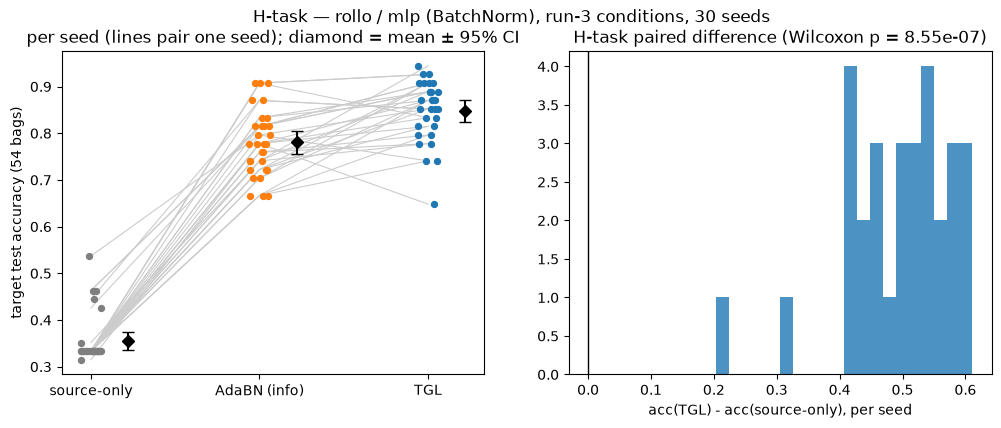

### Verdict H-task: **VALIDATED**

TGL 0.848 vs source-only 0.356; W = 465.0, one-sided p = 8.55e-07, rank-biserial = 1.00, HL = 0.500. AdaBN (information only): 0.780.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for i in range(len(tgl)):
    ax.plot([0, 1, 2], [floor[i], adabn[i], tgl[i]], color="0.8", lw=0.8, zorder=1)
jit = np.random.default_rng(0).uniform(-0.06, 0.06, len(tgl))
for x, v, color in ((0, floor, "tab:gray"), (1, adabn, "tab:orange"), (2, tgl, "tab:blue")):
    ax.scatter(x + jit, v, color=color, s=18, zorder=2)
    ax.errorbar(x + 0.22, v.mean(), yerr=1.96 * v.std(ddof=1) / np.sqrt(len(v)), fmt="D", color="k", capsize=4)
ax.set_xticks([0, 1, 2], ["source-only", "AdaBN (info)", "TGL"])
ax.set_ylabel("target test accuracy (54 bags)")
ax.set_title("per seed (lines pair one seed); diamond = mean ± 95% CI")
ax = axes[1]
ax.hist(tgl - floor, bins=20, color="tab:blue", alpha=0.8)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("acc(TGL) - acc(source-only), per seed")
ax.set_title(f"H-task paired difference (Wilcoxon p = {task_test['p']:.2e})")
fig.suptitle(f"H-task — rollo / mlp (BatchNorm), run-3 conditions, {len(tgl)} seeds")
save(fig, "h_task.png")
verdict("H-task", task_test["p"] < ALPHA,
        f"TGL {tgl.mean():.3f} vs source-only {floor.mean():.3f}; W = {task_test['statistic']:.1f}, "
        f"one-sided p = {task_test['p']:.2e}, rank-biserial = {task_test['rankBiserial']:.2f}, "
        f"HL = {task_test['hodgesLehmann']:.3f}. AdaBN (information only): {adabn.mean():.3f}.")

In [10]:
K1_ARMS = list(poc.K1_ARMS)
COLORS = {"TGL": "tab:blue", poc.NO_CONSENSUS: "tab:cyan", "abmil-published": "tab:red",
          "abmil-gated": "tab:orange", "max": "tab:purple", "mean": "tab:gray"}


def k1_family(runs, key, label, figname):
    seeds = sorted({s for (_, s) in runs})
    col = lambda r, arm, k="targetContrast": np.array([runs[(r, s)]["arms"][arm][k] for s in seeds])
    display(Markdown(f"**Per-seed target attention contrast, {label}** (units of 1/m; > 0 = contaminated get less weight)"))
    display(pd.DataFrame({(f"r={r}", arm): col(r, arm) for r in RATES for arm in ("TGL", poc.NO_CONSENSUS)},
                         index=pd.Index(seeds, name="seed")))
    rows = []
    for r in RATES:
        for arm in K1_ARMS:
            for side in ("target", "source"):
                s = poc.summary(col(r, arm, f"{side}Contrast"))
                rows.append({"rate": r, "arm": arm, "domain": side, "contrast mean": s["mean"], "sd": s["sd"],
                             "95% CI": "[{:.3f}, {:.3f}]".format(*s["ci95"]),
                             "contaminated mass": col(r, arm, f"{side}ContaminatedMass").mean(),
                             "uniform mass": r, "target acc": col(r, arm, "targetAccuracy").mean()})
    display(Markdown(f"**Summary over seeds, all arms, {label}**"))
    display(pd.DataFrame(rows).set_index(["rate", "arm", "domain"]))
    named = []
    for r in RATES:
        named.append((f"K1a r={r}: c(TGL) > 0", poc.paired_wilcoxon(col(r, "TGL"))))
        named.append((f"K1b r={r}: c(TGL) > c(TGL-NC)", poc.paired_wilcoxon(col(r, "TGL"), col(r, poc.NO_CONSENSUS))))
    tests = family_tests(named)
    TESTS[key] = tests
    display(pd.DataFrame([test_row(t["test"], t, t["pHolm"]) for t in tests]).set_index("test"))
    display(Markdown("**References, no criterion** (same one-sample test, unadjusted)"))
    display(pd.DataFrame([test_row(f"reference r={r}: c({arm}) > 0", poc.paired_wilcoxon(col(r, arm)))
                          for r in RATES for arm in poc.REFERENCE_MECHANISMS if arm != "mean"]).set_index("test"))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    ax = axes[0]
    for i, arm in enumerate(K1_ARMS):
        ax.errorbar(np.array(RATES) + (i - 2.5) * 0.006, [col(r, arm).mean() for r in RATES],
                    yerr=[1.96 * col(r, arm).std(ddof=1) / np.sqrt(len(seeds)) for r in RATES],
                    marker="o", capsize=3, color=COLORS[arm], label=arm)
    ax.axhline(0, color="k", lw=1)
    ax.set_xticks(RATES)
    ax.set_xlabel("contamination rate")
    ax.set_ylabel("attention contrast (x1/m), target test bags")
    ax.set_title(f"mean ± 95% CI over {len(seeds)} seeds")
    ax.legend(fontsize=8)
    ax = axes[1]
    data = [col(r, "TGL") - col(r, poc.NO_CONSENSUS) for r in RATES]
    ax.boxplot(data, tick_labels=[f"r={r}" for r in RATES])
    ax.axhline(0, color="k", lw=1)
    ax.set_ylabel("c(TGL) - c(TGL-NC), per seed")
    ax.set_title("K1b: consensus effect on the contrast")
    fig.suptitle(f"{key} — attention on contaminated vs clean instances ({label})")
    save(fig, figname)
    verdict(key, all(t["pHolm"] < ALPHA for t in tests),
            "; ".join(f"{t['test']}: p_Holm = {t['pHolm']:.2e}" for t in tests)
            + ". Mean contrasts c(TGL) / c(TGL-NC): "
            + ", ".join(f"r={r}: {col(r, 'TGL').mean():.3f} / {col(r, poc.NO_CONSENSUS).mean():.3f}" for r in RATES) + ".")


print("K1 family helper ready")

K1 family helper ready


## K1 — donor-class contamination (run 1's family, unchanged rule)

**Tested:** at each rate, the attention contrast of `TGL` on the target test
bags, and its paired difference with `TGL-NC`. The contaminants are points of
another class: atypical for their bag, typical globally. This is the regime
where only the consensus can act (§0.1).

**Per-seed target attention contrast, donor-class contamination** (units of 1/m; > 0 = contaminated get less weight)

r=0.1           r=0.2           r=0.3            
         TGL  TGL-NC     TGL  TGL-NC     TGL      TGL-NC
seed                                                    
10   -1.0678 -0.3082  0.1945 -0.0795  0.3418 -1.1572e-01
11   -0.1853 -1.0662  0.1586 -0.1961  0.2263 -8.0505e-02
12    0.0681 -0.1707  0.1055 -0.2879  0.2757 -1.2857e-01
13   -0.5114 -0.2415  0.2264 -0.0810 -0.0200 -2.2327e-02
14    0.1101 -0.0504  0.1268 -0.1557  0.2922 -5.0391e-02
15    0.1720  0.0084  0.2336 -0.3152  0.4336 -1.1070e-01
16   -0.4626 -0.1000 -0.2285 -0.1249  0.3432  9.4669e-05
17   -0.0801 -0.0261  0.1947 -0.0409  0.2081 -2.9277e-02
18    0.1902 -0.8010  0.1991  0.0114  0.2626 -5.7483e-02
19   -0.0056  0.0065  0.1140 -0.0834  0.3145 -4.2601e-02
20   -0.5707 -0.3547  0.2047 -0.5273  0.4377 -2.5614e-01
21   -1.9209 -0.5393  0.1226 -0.2955  0.3694 -2.0584e-01
22    0.1088 -0.0668  0.0375 -0.2037  0.2118 -2.7658e-02
23    0.2858 -0.0017  0.1620 -0.0329  0.2946  3.7795e-04
24    0.4107 -0.0200 -0.0943 -0.6751  0.4346 -1.9145e-02
25    0.0186 -0.3948  0.2688 -0.2736  0.0709 -1.0525e-01
26   -0.8203 -0.1730  0.3324 -0.0408 -0.1235 -4.7399e-01
27    0.2731 -0.4591 -0.1369 -0.0762  0.2977 -1.9016e-01
28    0.1312 -0.5036  0.1947  0.0146  0.3745 -1.0955e-03
29    0.0978 -0.1615  0.1287 -0.0364  0.2842 -4.5750e-02
30    0.0875 -0.2951  0.2853 -0.0467  0.2771 -5.6639e-02
31    0.3721 -0.2372  0.3323 -0.0024  0.3336 -1.4999e-01
32   -0.4461 -0.1790  0.2929 -0.0626  0.2739 -1.6031e-01
33    0.2974 -0.2195  0.1095  0.0052  0.3747 -2.7100e-03
34   -1.7437 -0.3433  0.1347 -0.1720  0.1060 -7.1411e-02
35    0.3746 -0.5665  0.2086 -0.4576  0.1827 -7.9510e-02
36   -2.3259 -0.0973  0.0173 -0.1339  0.3782 -1.3462e-01
37    0.0933 -0.1489  0.2289 -0.0311  0.1898 -2.6363e-01
38    0.1909 -0.3233  0.3532 -0.1810  0.3633 -2.5154e-01
39    0.2401 -0.2894  0.2478 -0.2753  0.2685 -2.9326e-02

**Summary over seeds, all arms, donor-class contamination**

contrast mean      sd            95% CI  \
rate arm             domain                                            
0.1  TGL             target        -0.2206  0.7061   [-0.484, 0.043]   
                     source        -0.0364  0.6437   [-0.277, 0.204]   
     TGL-NC          target        -0.2708  0.2460  [-0.363, -0.179]   
                     source        -0.3128  0.3000  [-0.425, -0.201]   
     abmil-published target        -2.9680  1.5245  [-3.537, -2.399]   
                     source        -3.2276  1.4757  [-3.779, -2.677]   
     abmil-gated     target        -2.2140  1.4368  [-2.751, -1.678]   
                     source        -2.4316  1.6495  [-3.048, -1.816]   
     max             target        -3.3951  0.9732  [-3.758, -3.032]   
                     source        -3.7449  1.1108  [-4.160, -3.330]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   
0.2  TGL             target         0.1585  0.1345    [0.108, 0.209]   
                     source         0.3115  0.1695    [0.248, 0.375]   
     TGL-NC          target        -0.1619  0.1677  [-0.225, -0.099]   
                     source        -0.1716  0.1760  [-0.237, -0.106]   
     abmil-published target        -1.4989  0.6489  [-1.741, -1.257]   
                     source        -1.5236  0.6117  [-1.752, -1.295]   
     abmil-gated     target        -1.1278  0.5348  [-1.328, -0.928]   
                     source        -1.1014  0.5634  [-1.312, -0.891]   
     max             target        -1.6782  0.4817  [-1.858, -1.498]   
                     source        -1.5625  0.5318  [-1.761, -1.364]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   
0.3  TGL             target         0.2693  0.1289    [0.221, 0.317]   
                     source         0.3805  0.1311    [0.332, 0.429]   
     TGL-NC          target        -0.1054  0.1054  [-0.145, -0.066]   
                     source        -0.1147  0.1023  [-0.153, -0.076]   
     abmil-published target        -0.8279  0.3972  [-0.976, -0.680]   
                     source        -0.8005  0.4002  [-0.950, -0.651]   
     abmil-gated     target        -0.6285  0.4253  [-0.787, -0.470]   
                     source        -0.7014  0.4364  [-0.864, -0.538]   
     max             target        -0.8818  0.4165  [-1.037, -0.726]   
                     source        -0.8025  0.3855  [-0.946, -0.659]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   

                             contaminated mass  uniform mass  target acc  
rate arm             domain                                               
0.1  TGL             target             0.1199           0.1      0.8407  
                     source             0.1033           0.1      0.8407  
     TGL-NC          target             0.1244           0.1      0.8660  
                     source             0.1281           0.1      0.8660  
     abmil-published target             0.3671           0.1      0.6037  
                     source             0.3905           0.1      0.6037  
     abmil-gated     target             0.2993           0.1      0.6889  
                     source             0.3188           0.1      0.6889  
     max             target             0.4056           0.1      0.4975  
                     source             0.4370           0.1      0.4975  
     mean            target             0.1000           0.1      0.8765  
                     source             0.1000           0.1      0.8765  
0.2  TGL             target             0.1746           0.2      0.8599  
                     source             0.1502           0.2      0.8599  
     TGL-NC          target             0.2259           0.2      0.8858  
                 

,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K1a r=0.1: c(TGL) > 0,30,30,214.0,6.4998e-01,6.4998e-01,-0.0796,-0.0586,"[-0.3484, 0.1297]"
K1b r=0.1: c(TGL) > c(TGL-NC),30,30,289.0,1.2672e-01,2.5344e-01,0.2430,0.1681,"[-0.1227, 0.3779]"
K1a r=0.2: c(TGL) > 0,30,30,430.0,3.9972e-06,1.1992e-05,0.8495,0.1749,"[0.1231, 0.2142]"
K1b r=0.2: c(TGL) > c(TGL-NC),30,30,462.0,4.6566e-09,2.3283e-08,0.9871,0.3145,"[0.2478, 0.3916]"
K1a r=0.3: c(TGL) > 0,30,30,460.0,9.3132e-09,3.7253e-08,0.9785,0.2842,"[0.2401, 0.3233]"
K1b r=0.3: c(TGL) > c(TGL-NC),30,30,465.0,9.3132e-10,5.5879e-09,1.0000,0.3751,"[0.3241, 0.4272]"


**References, no criterion** (same one-sample test, unadjusted)

,n,non-zero,W,p,rank-biserial,HL,HL 95% CI
test,,,,,,,
reference r=0.1: c(abmil-published) > 0,30,30,0.0,1.0,-1.0000,-3.0684,"[-3.6576, -2.4670]"
reference r=0.1: c(abmil-gated) > 0,30,30,1.0,1.0,-0.9957,-2.1922,"[-2.7854, -1.6216]"
reference r=0.1: c(max) > 0,30,30,0.0,1.0,-1.0000,-3.3128,"[-3.7243, -3.0041]"
reference r=0.2: c(abmil-published) > 0,30,30,0.0,1.0,-1.0000,-1.5028,"[-1.7823, -1.2743]"
reference r=0.2: c(abmil-gated) > 0,30,30,0.0,1.0,-1.0000,-1.1444,"[-1.3690, -0.9226]"
reference r=0.2: c(max) > 0,30,30,0.0,1.0,-1.0000,-1.7014,"[-1.8750, -1.4699]"
reference r=0.3: c(abmil-published) > 0,30,30,0.0,1.0,-1.0000,-0.8032,"[-0.9713, -0.6798]"
reference r=0.3: c(abmil-gated) > 0,30,30,0.0,1.0,-1.0000,-0.6172,"[-0.7965, -0.4501]"
reference r=0.3: c(max) > 0,30,30,0.0,1.0,-1.0000,-0.9083,"[-1.0406, -0.7319]"


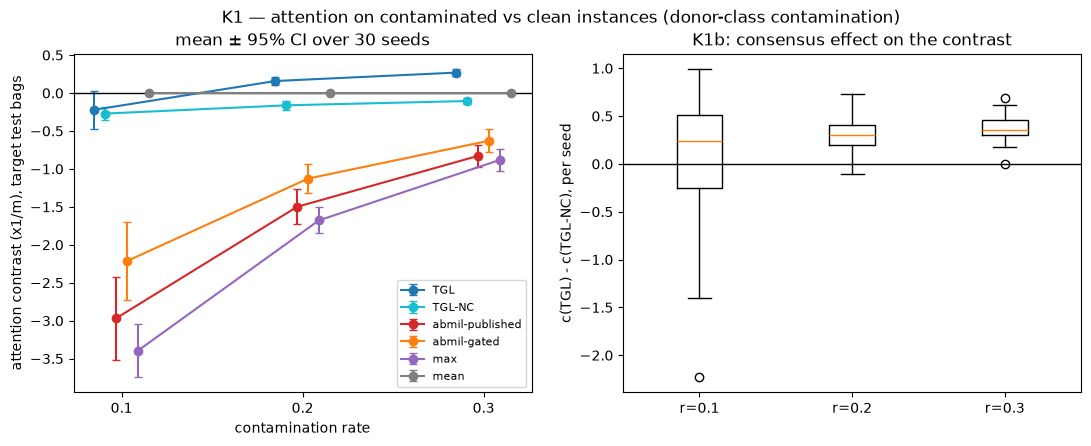

### Verdict K1: **NOT VALIDATED**

K1a r=0.1: c(TGL) > 0: p_Holm = 6.50e-01; K1b r=0.1: c(TGL) > c(TGL-NC): p_Holm = 2.53e-01; K1a r=0.2: c(TGL) > 0: p_Holm = 1.20e-05; K1b r=0.2: c(TGL) > c(TGL-NC): p_Holm = 2.33e-08; K1a r=0.3: c(TGL) > 0: p_Holm = 3.73e-08; K1b r=0.3: c(TGL) > c(TGL-NC): p_Holm = 5.59e-09. Mean contrasts c(TGL) / c(TGL-NC): r=0.1: -0.221 / -0.271, r=0.2: 0.159 / -0.162, r=0.3: 0.269 / -0.105.

In [11]:
k1_family(K1_DONOR, "K1", "donor-class contamination", "k1_donor.png")

## K1-artifact — off-manifold artifacts (separate family, same rule)

**Tested:** the same contrasts, with the same slots now holding artifacts:
the clean instance plus noise of sd 1·esc. They are atypical globally *and*
for their bag, as the protocol's marked windows are. Here relevance and ABMIL
can also detect them, so K1b asks whether consensus adds anything beyond
relevance (§0.1).

**Per-seed target attention contrast, artifact contamination** (units of 1/m; > 0 = contaminated get less weight)

r=0.1           r=0.2           r=0.3        
         TGL  TGL-NC     TGL  TGL-NC     TGL  TGL-NC
seed                                                
10    0.1946  0.0001  0.3882 -0.0495  0.3457 -0.2433
11    0.3712 -0.0437  0.2743  0.0987  0.1890  0.1851
12   -0.0036  0.1078  0.2443  0.0766  0.4269  0.0107
13    0.1594 -0.1357  0.2516 -0.0631  0.2909  0.0216
14   -0.4904  0.0180  0.4087  0.0958  0.3547 -0.0491
15    0.3021 -0.0179  0.2056 -0.0460  0.2848 -0.0004
16    0.3393 -0.0893  0.3247 -0.3097  0.1342 -0.0199
17    0.1681 -0.5459  0.3033  0.1191  0.3591  0.0645
18   -0.0494 -0.0753  0.1310  0.0807  0.3783 -0.0126
19    0.4625 -0.2652  0.2513 -0.0947  0.5093 -0.4713
20   -0.0517 -0.0606  0.3463  0.0921  0.2766 -0.1325
21   -0.0418 -0.0447  0.2657 -0.0282  0.3068  0.0141
22    0.3079 -0.0190  0.3583 -0.3511  0.2550  0.0487
23    0.1613  0.0770  0.1259 -0.1248  0.3837  0.1685
24    0.3275 -0.3454  0.2774  0.0767  0.4701  0.0198
25   -0.1084  0.0999  0.1804 -0.0239  0.1359  0.0715
26    0.3109 -0.0503  0.2592 -0.0524  0.0793 -0.0341
27    0.0097  0.0164  0.3445  0.0281  0.3916  0.0757
28    0.3137  0.1084  0.3114  0.1098  0.2173  0.1329
29    0.1704 -0.2423  0.2791 -0.0984  0.2146 -0.0350
30   -0.0330 -0.2609  0.3648  0.0722  0.3920  0.0066
31    0.1986 -0.5720  0.2785  0.0263  0.5008  0.0221
32    0.3323 -0.1876  0.2266  0.0128  0.3055 -0.2382
33    0.1077 -0.0508  0.2732 -0.0161  0.4290  0.0453
34    0.1262 -0.1934 -0.6684 -0.0726  0.3318 -0.0533
35    0.0728  0.0300  0.2618  0.0011  0.2928  0.0127
36    0.3027  0.2092  0.3211 -0.0477  0.1282 -0.3069
37   -0.6027 -0.0698  0.3564 -0.0647 -0.0281 -0.0567
38   -0.3130 -0.0140  0.3655  0.1463  0.2781  0.0557
39    0.2110 -0.5297  0.2769  0.0057  0.2787  0.1280

**Summary over seeds, all arms, artifact contamination**

contrast mean      sd            95% CI  \
rate arm             domain                                            
0.1  TGL             target         0.1085  0.2484    [0.016, 0.201]   
                     source         0.3216  0.2060    [0.245, 0.399]   
     TGL-NC          target        -0.1049  0.1947  [-0.178, -0.032]   
                     source        -0.1086  0.1784  [-0.175, -0.042]   
     abmil-published target        -1.4798  1.0676  [-1.878, -1.081]   
                     source        -1.5880  1.2583  [-2.058, -1.118]   
     abmil-gated     target        -0.5035  0.7909  [-0.799, -0.208]   
                     source        -0.6237  0.7128  [-0.890, -0.358]   
     max             target        -4.9588  1.5844  [-5.550, -4.367]   
                     source        -5.3155  1.4160  [-5.844, -4.787]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   
0.2  TGL             target         0.2529  0.1870    [0.183, 0.323]   
                     source         0.4610  0.1795    [0.394, 0.528]   
     TGL-NC          target        -0.0134  0.1134   [-0.056, 0.029]   
                     source        -0.0504  0.1439   [-0.104, 0.003]   
     abmil-published target        -0.6016  0.7571  [-0.884, -0.319]   
                     source        -0.6042  0.6532  [-0.848, -0.360]   
     abmil-gated     target        -0.2654  0.5018  [-0.453, -0.078]   
                     source        -0.3912  0.5901  [-0.612, -0.171]   
     max             target        -3.7307  0.9287  [-4.077, -3.384]   
                     source        -3.8966  0.8902  [-4.229, -3.564]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   
0.3  TGL             target         0.2971  0.1254    [0.250, 0.344]   
                     source         0.5776  0.1108    [0.536, 0.619]   
     TGL-NC          target        -0.0190  0.1404   [-0.071, 0.033]   
                     source        -0.0211  0.1278   [-0.069, 0.027]   
     abmil-published target        -0.4216  0.7113  [-0.687, -0.156]   
                     source        -0.4976  0.7190  [-0.766, -0.229]   
     abmil-gated     target        -0.0659  0.4557   [-0.236, 0.104]   
                     source        -0.0785  0.3065   [-0.193, 0.036]   
     max             target        -2.8660  0.4769  [-3.044, -2.688]   
                     source        -2.9894  0.4073  [-3.142, -2.837]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   

                             contaminated mass  uniform mass  target acc  
rate arm             domain                                               
0.1  TGL             target             0.0902           0.1      0.8272  
                     source             0.0711           0.1      0.8272  
     TGL-NC          target             0.1094           0.1      0.8296  
                     source             0.1098           0.1      0.8296  
     abmil-published target             0.2332           0.1      0.7259  
                     source             0.2429           0.1      0.7259  
     abmil-gated     target             0.1453           0.1      0.7710  
                     source             0.1561           0.1      0.7710  
     max             target             0.5463           0.1      0.6765  
                     source             0.5784           0.1      0.6765  
     mean            target             0.1000           0.1      0.8179  
                     source             0.1000           0.1      0.8179  
0.2  TGL             target             0.1595           0.2      0.8198  
                     source             0.1262           0.2      0.8198  
     TGL-NC          target             0.2021           0.2      0.8086  
                 

,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K1a r=0.1: c(TGL) > 0,30,30,356.0,4.9658e-03,4.9658e-03,0.5312,0.1403,"[0.0513, 0.2200]"
K1b r=0.1: c(TGL) > c(TGL-NC),30,30,380.0,8.5930e-04,1.7186e-03,0.6344,0.2157,"[0.0939, 0.3613]"
K1a r=0.2: c(TGL) > 0,30,30,435.0,1.8952e-06,5.6857e-06,0.8710,0.2813,"[0.2545, 0.3114]"
K1b r=0.2: c(TGL) > c(TGL-NC),30,30,437.0,1.3812e-06,5.5246e-06,0.8796,0.2728,"[0.2357, 0.3141]"
K1a r=0.3: c(TGL) > 0,30,30,464.0,1.8626e-09,9.3132e-09,0.9957,0.3033,"[0.2541, 0.3486]"
K1b r=0.3: c(TGL) > c(TGL-NC),30,30,465.0,9.3132e-10,5.5879e-09,1.0000,0.3040,"[0.2413, 0.3716]"


**References, no criterion** (same one-sample test, unadjusted)

,n,non-zero,W,p,rank-biserial,HL,HL 95% CI
test,,,,,,,
reference r=0.1: c(abmil-published) > 0,30,30,4.0,1.0000,-0.9828,-1.4048,"[-1.8881, -1.0175]"
reference r=0.1: c(abmil-gated) > 0,30,30,41.0,1.0000,-0.8237,-0.3450,"[-0.6057, -0.1834]"
reference r=0.1: c(max) > 0,30,30,0.0,1.0000,-1.0000,-4.9588,"[-5.5761, -4.3416]"
reference r=0.2: c(abmil-published) > 0,30,30,40.0,1.0000,-0.8280,-0.4858,"[-0.7702, -0.2579]"
reference r=0.2: c(abmil-gated) > 0,30,30,118.0,0.9918,-0.4925,-0.1284,"[-0.4258, -0.0159]"
reference r=0.2: c(max) > 0,30,30,0.0,1.0000,-1.0000,-3.7847,"[-4.1319, -3.4375]"
reference r=0.3: c(abmil-published) > 0,30,30,108.0,0.9956,-0.5355,-0.2829,"[-0.7002, -0.0372]"
reference r=0.3: c(abmil-gated) > 0,30,30,279.0,0.1746,0.2000,0.0510,"[-0.0457, 0.1152]"
reference r=0.3: c(max) > 0,30,30,0.0,1.0000,-1.0000,-2.9365,"[-3.0688, -2.7601]"


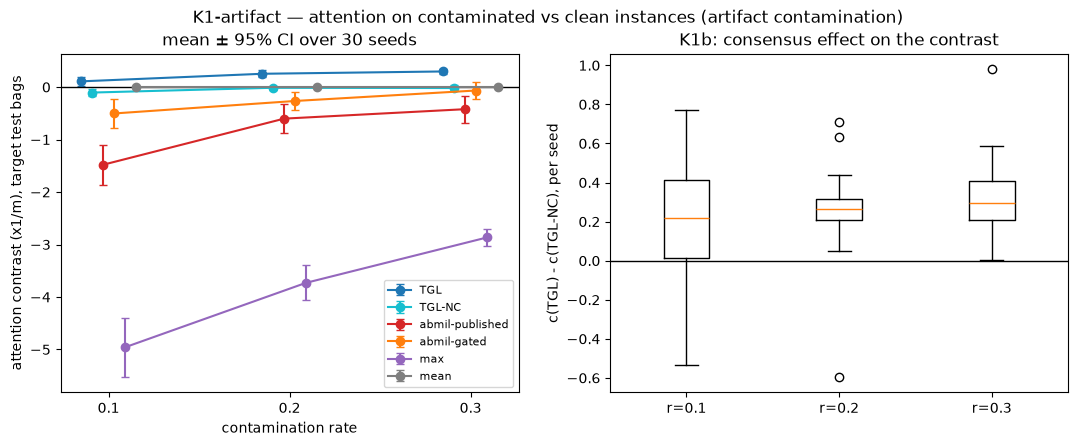

### Verdict K1-artifact: **VALIDATED**

K1a r=0.1: c(TGL) > 0: p_Holm = 4.97e-03; K1b r=0.1: c(TGL) > c(TGL-NC): p_Holm = 1.72e-03; K1a r=0.2: c(TGL) > 0: p_Holm = 5.69e-06; K1b r=0.2: c(TGL) > c(TGL-NC): p_Holm = 5.52e-06; K1a r=0.3: c(TGL) > 0: p_Holm = 9.31e-09; K1b r=0.3: c(TGL) > c(TGL-NC): p_Holm = 5.59e-09. Mean contrasts c(TGL) / c(TGL-NC): r=0.1: 0.109 / -0.105, r=0.2: 0.253 / -0.013, r=0.3: 0.297 / -0.019.

In [12]:
k1_family(K1_ART, "K1-artifact", "artifact contamination", "k1_artifact.png")

## K2 — the target bag lies closer to its own partner, more with the local term

**Tested:** per seed, on the clean run-3 material (k = 4 and the subject
field), the within-class partner separation of `TGL` (> 0) and its paired
difference with the global-only arm `TG`. Reported without criterion: the
across-class separation, the local term's conditional partner mass (chance
1/18) and the source-only floor.

In [13]:
def k2(arm, key):
    if arm == "source-only":
        return np.array([LADDER[s]["sourceOnlyPartner"][key] for s in sorted(LADDER)])
    return np.array([LADDER[s]["arms"][arm]["partner"][key] for s in sorted(LADDER)])


sep_tgl, sep_tg = k2("TGL", "separationWithin"), k2("TG", "separationWithin")
chance = LADDER[SEEDS[0]]["arms"]["TGL"]["partner"]["partnerMassChance"]
display(pd.DataFrame({"seed": sorted(LADDER), "s(TGL)": sep_tgl, "s(TG)": sep_tg, "s(TGL) - s(TG)": sep_tgl - sep_tg,
                      "s(source-only)": k2("source-only", "separationWithin"),
                      "partner mass TGL": k2("TGL", "partnerMass"),
                      "partner mass TG": k2("TG", "partnerMass")}).set_index("seed"))
display(summary_rows({"s within class, TGL": sep_tgl, "s within class, TG": sep_tg,
                      "s within class, source-only": k2("source-only", "separationWithin"),
                      "s(TGL) - s(TG)": sep_tgl - sep_tg,
                      "s across classes, TGL (info)": k2("TGL", "separationAcross"),
                      "s across classes, TG (info)": k2("TG", "separationAcross"),
                      "distance to own partner, TGL": k2("TGL", "ownDistance"),
                      "distance to own partner, TG": k2("TG", "ownDistance"),
                      f"partner mass, TGL (chance {chance:.3f})": k2("TGL", "partnerMass"),
                      f"partner mass, TG (chance {chance:.3f})": k2("TG", "partnerMass")}))
TESTS["K2"] = family_tests([("K2a: s(TGL) > 0", poc.paired_wilcoxon(sep_tgl)),
                            ("K2b: s(TGL) > s(TG)", poc.paired_wilcoxon(sep_tgl, sep_tg))])
info = poc.paired_wilcoxon(k2("TGL", "partnerMass") - chance)
display(pd.DataFrame([test_row(t["test"], t, t["pHolm"]) for t in TESTS["K2"]]
                     + [test_row("info: partner mass TGL > chance", info)]).set_index("test"))

,s(TGL),s(TG),s(TGL) - s(TG),s(source-only),partner mass TGL,partner mass TG
seed,,,,,,
10,0.0598,0.0393,0.0205,2.6731e-04,0.0642,0.0597
11,0.0528,0.0346,0.0182,6.6724e-05,0.0627,0.0624
12,0.0432,0.0250,0.0182,-9.6910e-04,0.0618,0.0596
13,0.0172,0.0197,-0.0025,-1.3903e-03,0.0575,0.0576
14,0.0747,0.0272,0.0475,-3.9959e-04,0.0659,0.0586
15,0.0650,0.1191,-0.0540,1.6706e-03,0.0649,0.0787
16,0.0211,0.0260,-0.0049,4.8781e-04,0.0581,0.0590
17,0.0452,0.1207,-0.0755,-1.1831e-03,0.0628,0.0783
18,0.0975,0.1008,-0.0033,-1.5600e-03,0.0736,0.0760


,mean,sd,95% CI,median,n
quantity,,,,,
"s within class, TGL",0.0520,0.0228,"[0.0435, 0.0605]",0.0514,30
"s within class, TG",0.0566,0.0320,"[0.0447, 0.0685]",0.0518,30
"s within class, source-only",-0.0005,0.0009,"[-0.0008, -0.0001]",-0.0004,30
s(TGL) - s(TG),-0.0046,0.0262,"[-0.0144, 0.0052]",-0.0031,30
"s across classes, TGL (info)",0.0841,0.0347,"[0.0711, 0.0971]",0.0808,30
"s across classes, TG (info)",0.0897,0.0426,"[0.0737, 0.1056]",0.0819,30
"distance to own partner, TGL",0.6979,0.0377,"[0.6838, 0.7119]",0.6916,30
"distance to own partner, TG",0.7526,0.0430,"[0.7366, 0.7687]",0.7524,30
"partner mass, TGL (chance 0.056)",0.0632,0.0038,"[0.0618, 0.0646]",0.0631,30


,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K2a: s(TGL) > 0,30,30,465.0,9.3132e-10,1.8626e-09,1.0000,0.0516,"[0.0431, 0.0606]"
K2b: s(TGL) > s(TG),30,30,188.0,8.2006e-01,8.2006e-01,-0.1914,-0.0037,"[-0.0117, 0.0058]"
info: partner mass TGL > chance,30,30,465.0,9.3132e-10,NaN,1.0000,0.0075,"[0.0061, 0.0090]"


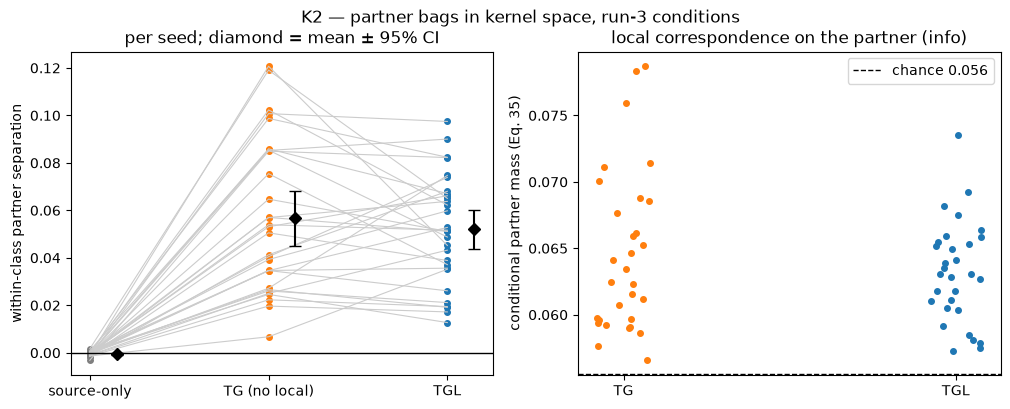

### Verdict K2: **NOT VALIDATED**

K2a: s(TGL) > 0: p_Holm = 1.86e-09; K2b: s(TGL) > s(TG): p_Holm = 8.20e-01. Mean separation TGL 0.0520, TG 0.0566; partner mass TGL 0.063 (chance 0.056).

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
so = k2("source-only", "separationWithin")
for i in range(len(sep_tgl)):
    ax.plot([0, 1, 2], [so[i], sep_tg[i], sep_tgl[i]], color="0.8", lw=0.8)
for x, v, color in ((0, so, "tab:gray"), (1, sep_tg, "tab:orange"), (2, sep_tgl, "tab:blue")):
    ax.scatter(np.full(len(v), x), v, color=color, s=16)
    ax.errorbar(x + 0.15, v.mean(), yerr=1.96 * v.std(ddof=1) / np.sqrt(len(v)), fmt="D", color="k", capsize=4)
ax.axhline(0, color="k", lw=1)
ax.set_xticks([0, 1, 2], ["source-only", "TG (no local)", "TGL"])
ax.set_ylabel("within-class partner separation")
ax.set_title("per seed; diamond = mean ± 95% CI")
ax = axes[1]
for x, arm, color in ((0, "TG", "tab:orange"), (1, "TGL", "tab:blue")):
    v = k2(arm, "partnerMass")
    ax.scatter(np.full(len(v), x) + np.random.default_rng(x).uniform(-0.08, 0.08, len(v)), v, color=color, s=16)
ax.axhline(chance, color="k", ls="--", lw=1, label=f"chance {chance:.3f}")
ax.set_xticks([0, 1], ["TG", "TGL"])
ax.set_ylabel("conditional partner mass (Eq. 35)")
ax.set_title("local correspondence on the partner (info)")
ax.legend()
fig.suptitle("K2 — partner bags in kernel space, run-3 conditions")
save(fig, "k2_partners.png")
verdict("K2", all(t["pHolm"] < ALPHA for t in TESTS["K2"]),
        "; ".join(f"{t['test']}: p_Holm = {t['pHolm']:.2e}" for t in TESTS["K2"])
        + f". Mean separation TGL {sep_tgl.mean():.4f}, TG {sep_tg.mean():.4f}; "
        f"partner mass TGL {k2('TGL', 'partnerMass').mean():.3f} (chance {chance:.3f}).")

In [15]:
def k3_family(ladder, key, label, figname):
    acc = {arm: column(ladder, arm, "targetAccuracy") for arm in ("TGL", poc.NO_CONSENSUS, "TG", "TL")}
    seeds = sorted(ladder)
    display(pd.DataFrame({"seed": seeds, **acc, "TGL - TGL-NC": acc["TGL"] - acc[poc.NO_CONSENSUS],
                          "TGL - TG": acc["TGL"] - acc["TG"], "TGL - TL": acc["TGL"] - acc["TL"]}).set_index("seed"))
    display(summary_rows({**acc, "TGL - TGL-NC": acc["TGL"] - acc[poc.NO_CONSENSUS],
                          "TGL - TG": acc["TGL"] - acc["TG"], "TGL - TL": acc["TGL"] - acc["TL"],
                          "source-only (shared phase 1)": column(ladder, "TGL", "sourceOnlyTargetAccuracy"),
                          "AdaBN (info)": column(ladder, "TGL", "adabnTargetAccuracy")}))
    tag = "" if key == "K3" else " [artifact]"
    tests = family_tests([(f"K3a{tag}: TGL > TGL-NC", poc.paired_wilcoxon(acc["TGL"], acc[poc.NO_CONSENSUS])),
                          (f"K3b{tag}: TGL > TG", poc.paired_wilcoxon(acc["TGL"], acc["TG"])),
                          (f"K3c{tag}: TGL > TL", poc.paired_wilcoxon(acc["TGL"], acc["TL"]))])
    TESTS[key] = tests
    display(pd.DataFrame([test_row(t["test"], t, t["pHolm"]) for t in tests]).set_index("test"))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    names = [poc.NO_CONSENSUS, "TG", "TL", "TGL"]
    axes[0].boxplot([acc[n] for n in names], tick_labels=names)
    axes[0].set_ylabel("target test accuracy (54 bags)")
    axes[0].set_title(f"the four rungs, {len(seeds)} seeds ({label})")
    diffs = [acc["TGL"] - acc[n] for n in (poc.NO_CONSENSUS, "TG", "TL")]
    axes[1].boxplot(diffs, tick_labels=["TGL - TGL-NC", "TGL - TG", "TGL - TL"])
    axes[1].axhline(0, color="k", lw=1)
    axes[1].set_ylabel("paired difference per seed")
    axes[1].set_title(", ".join(f"p_Holm={t['pHolm']:.1e}" for t in tests))
    fig.suptitle(f"{key} — ablation ladder ({label})")
    save(fig, figname)
    verdict(key, all(t["pHolm"] < ALPHA for t in tests),
            "; ".join(f"{t['test']}: mean diff {np.mean(d):+.3f}, HL {t['hodgesLehmann']:+.3f}, p_Holm = {t['pHolm']:.2e}"
                      for t, d in zip(tests, diffs))
            + ". Means: " + ", ".join(f"{n} {acc[n].mean():.3f}" for n in names) + ".")
    return acc


print("K3 family helper ready")

K3 family helper ready


## K3 — the ladder on clean bags (run 1's family, unchanged rule)

**Tested:** per seed, target test accuracy of `TGL` against `TGL-NC` (the
consensus), `TG` (the local term) and `TL` (the global term), under the run-3
conditions on clean bags. §0.1 predicts that the consensus rung cannot show
anything on clean bags.

,TGL,TGL-NC,TG,TL,TGL - TGL-NC,TGL - TG,TGL - TL
seed,,,,,,,
10,0.7963,0.5741,0.8148,0.7778,0.2222,-0.0185,0.0185
11,0.9259,0.5556,0.8704,0.8148,0.3704,0.0556,0.1111
12,0.9074,0.9074,0.9074,0.8889,0.0000,0.0000,0.0185
13,0.9444,0.7963,0.9074,0.6111,0.1481,0.0370,0.3333
14,0.8148,0.6852,0.7593,0.6481,0.1296,0.0556,0.1667
15,0.8333,0.8519,0.9074,0.8148,-0.0185,-0.0741,0.0185
16,0.8889,0.9444,0.9630,0.8704,-0.0556,-0.0741,0.0185
17,0.8704,0.8519,0.7037,0.9074,0.0185,0.1667,-0.0370
18,0.9074,0.6481,0.8889,0.8704,0.2593,0.0185,0.0370


,mean,sd,95% CI,median,n
quantity,,,,,
TGL,0.8481,0.0657,"[0.8236, 0.8727]",0.8611,30
TGL-NC,0.8130,0.1090,"[0.7723, 0.8537]",0.8333,30
TG,0.8426,0.0729,"[0.8154, 0.8698]",0.8611,30
TL,0.8216,0.1087,"[0.7810, 0.8622]",0.8519,30
TGL - TGL-NC,0.0352,0.1225,"[-0.0106, 0.0809]",0.0093,30
TGL - TG,0.0056,0.0644,"[-0.0185, 0.0296]",0.0000,30
TGL - TL,0.0265,0.1083,"[-0.0139, 0.0670]",0.0185,30
source-only (shared phase 1),0.3556,0.0531,"[0.3357, 0.3754]",0.3333,30
AdaBN (info),0.7802,0.0699,"[0.7541, 0.8064]",0.7778,30


,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K3a: TGL > TGL-NC,30,26,231.0,0.0792,0.2376,0.3162,0.0278,"[-0.0185, 0.0741]"
K3b: TGL > TG,30,26,188.5,0.3703,0.3703,0.0741,0.0000,"[-0.0185, 0.0278]"
K3c: TGL > TL,30,27,236.5,0.1266,0.2532,0.2513,0.0185,"[-0.0185, 0.0648]"


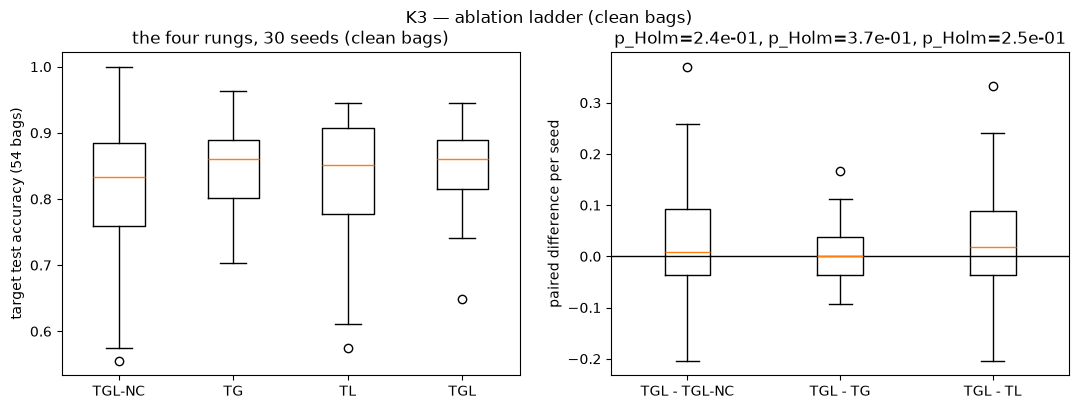

### Verdict K3: **NOT VALIDATED**

K3a: TGL > TGL-NC: mean diff +0.035, HL +0.028, p_Holm = 2.38e-01; K3b: TGL > TG: mean diff +0.006, HL +0.000, p_Holm = 3.70e-01; K3c: TGL > TL: mean diff +0.027, HL +0.019, p_Holm = 2.53e-01. Means: TGL-NC 0.813, TG 0.843, TL 0.822, TGL 0.848.

In [16]:
ACC_CLEAN = k3_family(LADDER, "K3", "clean bags", "k3_clean.png")

## K3-artifact — the ladder on artifact-contaminated bags (separate family, same rule)

**Tested:** the same rungs, trained and scored on bags whose train and test
roles carry artifacts at r = 0.2 in both domains (§0.1: the consensus rung
needs instances that corrupt a mean).

,TGL,TGL-NC,TG,TL,TGL - TGL-NC,TGL - TG,TGL - TL
seed,,,,,,,
10,0.7963,0.8148,0.8148,0.5741,-0.0185,-0.0185,0.2222
11,0.7222,0.7407,0.6481,0.6667,-0.0185,0.0741,0.0556
12,0.8333,0.7407,0.8148,0.7963,0.0926,0.0185,0.0370
13,0.8704,0.6481,0.8148,0.8889,0.2222,0.0556,-0.0185
14,0.8704,0.7407,0.8519,0.8704,0.1296,0.0185,0.0000
15,0.8889,0.9815,0.9259,0.9074,-0.0926,-0.0370,-0.0185
16,0.7593,0.7037,0.8704,0.8519,0.0556,-0.1111,-0.0926
17,0.8889,0.8148,0.9630,0.8889,0.0741,-0.0741,0.0000
18,0.6852,0.8704,0.6481,0.6852,-0.1852,0.0370,0.0000


,mean,sd,95% CI,median,n
quantity,,,,,
TGL,0.8198,0.0766,"[0.7912, 0.8483]",0.8148,30
TGL-NC,0.8086,0.0893,"[0.7753, 0.8420]",0.8148,30
TG,0.8173,0.0956,"[0.7816, 0.8530]",0.8148,30
TL,0.7951,0.0985,"[0.7583, 0.8318]",0.8241,30
TGL - TGL-NC,0.0111,0.1079,"[-0.0292, 0.0514]",0.0093,30
TGL - TG,0.0025,0.0762,"[-0.0260, 0.0309]",0.0000,30
TGL - TL,0.0247,0.0898,"[-0.0089, 0.0582]",0.0000,30
source-only (shared phase 1),0.3593,0.0375,"[0.3452, 0.3733]",0.3333,30
AdaBN (info),0.7605,0.0964,"[0.7245, 0.7965]",0.7593,30


,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K3a [artifact]: TGL > TGL-NC,30,27,219.0,0.2354,0.4708,0.1587,0.0093,"[-0.0278, 0.0556]"
K3b [artifact]: TGL > TG,30,27,198.0,0.4141,0.4708,0.0476,0.0000,"[-0.0278, 0.0278]"
K3c [artifact]: TGL > TL,30,23,184.0,0.0807,0.2421,0.3333,0.0185,"[-0.0093, 0.0556]"


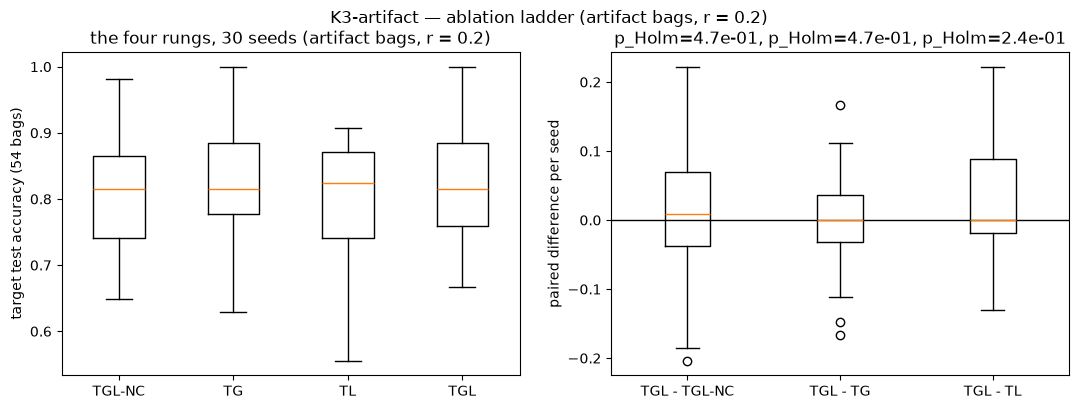

### Verdict K3-artifact: **NOT VALIDATED**

K3a [artifact]: TGL > TGL-NC: mean diff +0.011, HL +0.009, p_Holm = 4.71e-01; K3b [artifact]: TGL > TG: mean diff +0.002, HL +0.000, p_Holm = 4.71e-01; K3c [artifact]: TGL > TL: mean diff +0.025, HL +0.019, p_Holm = 2.42e-01. Means: TGL-NC 0.809, TG 0.817, TL 0.795, TGL 0.820.

In [17]:
ACC_ART = k3_family(LADDER_ART, "K3-artifact", f"artifact bags, r = {ARTIFACT_LADDER_RATE}", "k3_artifact.png")

## Summary of all hypotheses (run 3)

In [18]:
RULES = {"H-task": "Wilcoxon TGL > source-only, p < 0.05",
         "K1": "6 tests (K1a, K1b x 3 rates), donor, all Holm p < 0.05",
         "K1-artifact": "6 tests (K1a, K1b x 3 rates), artifact, all Holm p < 0.05",
         "K2": "s(TGL) > 0 and s(TGL) > s(TG), both Holm p < 0.05",
         "K3": "TGL > TGL-NC, TG, TL on clean bags, all Holm p < 0.05",
         "K3-artifact": "TGL > TGL-NC, TG, TL on artifact bags, all Holm p < 0.05"}
final = pd.DataFrame([{"hypothesis": h, "rule": RULES[h], "verdict": VERDICTS[h]["verdict"]} for h in RULES]).set_index("hypothesis")
display(final)
report = {"preregistration": PREREGISTRATION, "verdicts": VERDICTS, "tests": TESTS,
          "batterySeconds": BATTERY_SECONDS, "workers": WORKERS, "seedsOf": SEEDS_OF}
(RESULTS / "verdicts.json").write_text(json.dumps(report, indent=2, default=float) + "\n")
print("VALIDATED:", int((final["verdict"] == "VALIDATED").sum()), "of", len(final))
print("written:", sorted(p.name for p in RESULTS.iterdir()))

,rule,verdict
hypothesis,,
H-task,"Wilcoxon TGL > source-only, p < 0.05",VALIDATED
K1,"6 tests (K1a, K1b x 3 rates), donor, all Holm ...",NOT VALIDATED
K1-artifact,"6 tests (K1a, K1b x 3 rates), artifact, all Ho...",VALIDATED
K2,"s(TGL) > 0 and s(TGL) > s(TG), both Holm p < 0.05",NOT VALIDATED
K3,"TGL > TGL-NC, TG, TL on clean bags, all Holm p...",NOT VALIDATED
K3-artifact,"TGL > TGL-NC, TG, TL on artifact bags, all Hol...",NOT VALIDATED


VALIDATED: 2 of 6
written: ['h_task.png', 'k1_artifact.png', 'k1_donor.png', 'k2_partners.png', 'k3_artifact.png', 'k3_clean.png', 'preregistration.json', 'raw_results.json', 'verdicts.json']


## Run 1 / run 2 / run 3

Same seeds, rates, hyperparameters, contrasts, tests and rules. Runs 1 and 2
are read from their `verdicts.json`, never retyped. The artifact families
exist only in run 3.

In [19]:
def tests_of(path):
    report = json.loads(path.read_text())
    out = {"H-task: TGL > source-only": report["tests"]["H-task"]}
    for family in ("K1", "K2", "K3"):
        out.update({t["test"]: t for t in report["tests"][family]})
    return report, out


r1, t1 = tests_of(RUN1 / "verdicts.json")
r2, t2 = tests_of(RUN2 / "verdicts.json")
t3 = {"H-task: TGL > source-only": TESTS["H-task"]}
for family in ("K1", "K2", "K3"):
    t3.update({t["test"]: t for t in TESTS[family]})
rows = []
for name in t1:
    rows.append({"test": name,
                 **{f"HL run {i}": t[name]["hodgesLehmann"] for i, t in ((1, t1), (2, t2), (3, t3))},
                 **{f"p (Holm) run {i}": t[name].get("pHolm", t[name]["p"]) for i, t in ((1, t1), (2, t2), (3, t3))}})
display(Markdown("**Per test** (H-task is a single test, so its p is unadjusted)"))
display(pd.DataFrame(rows).set_index("test"))
side = pd.DataFrame([{"hypothesis": h,
                      "run 1 (global shift)": r1["verdicts"].get(h, {}).get("verdict", "not run"),
                      "run 2 (+ per-pair shift)": r2["verdicts"].get(h, {}).get("verdict", "not run"),
                      "run 3 (conditions)": VERDICTS[h]["verdict"]} for h in RULES]).set_index("hypothesis")
display(Markdown("**Per hypothesis family**"))
display(side)
print("VALIDATED ->", {c: int((side[c] == "VALIDATED").sum()) for c in side.columns})

**Per test** (H-task is a single test, so its p is unadjusted)

,HL run 1,HL run 2,HL run 3,p (Holm) run 1,p (Holm) run 2,p (Holm) run 3
test,,,,,,
H-task: TGL > source-only,0.5000,0.4722,0.5000,8.2865e-07,8.0478e-07,8.5472e-07
K1a r=0.1: c(TGL) > 0,0.0010,-0.0252,-0.0586,5.0000e-01,7.0110e-01,6.4998e-01
K1b r=0.1: c(TGL) > c(TGL-NC),0.2204,0.2498,0.1681,1.3058e-02,7.5189e-03,2.5344e-01
K1a r=0.2: c(TGL) > 0,0.0984,0.1187,0.1749,1.3058e-02,7.5189e-03,1.1992e-05
K1b r=0.2: c(TGL) > c(TGL-NC),0.2233,0.2564,0.3145,4.0978e-07,1.2293e-07,2.3283e-08
K1a r=0.3: c(TGL) > 0,0.2028,0.2061,0.2842,5.5879e-09,9.3132e-09,3.7253e-08
K1b r=0.3: c(TGL) > c(TGL-NC),0.2642,0.2596,0.3751,5.5879e-09,5.5879e-09,5.5879e-09
K2a: s(TGL) > 0,0.0283,0.0204,0.0516,3.7253e-09,2.7623e-06,1.8626e-09
K2b: s(TGL) > s(TG),-0.0056,-0.0148,-0.0037,8.3063e-01,9.9668e-01,8.2006e-01


**Per hypothesis family**

,run 1 (global shift),run 2 (+ per-pair shift),run 3 (conditions)
hypothesis,,,
H-task,VALIDATED,VALIDATED,VALIDATED
K1,NOT VALIDATED,NOT VALIDATED,NOT VALIDATED
K1-artifact,not run,not run,VALIDATED
K2,NOT VALIDATED,NOT VALIDATED,NOT VALIDATED
K3,NOT VALIDATED,NOT VALIDATED,NOT VALIDATED
K3-artifact,not run,not run,NOT VALIDATED


VALIDATED -> {'run 1 (global shift)': 1, 'run 2 (+ per-pair shift)': 1, 'run 3 (conditions)': 2}
